In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [4]:
df_amazon = pd.read_csv("../lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

In [ ]:
## Part 1: Understanding Product Categories

In [6]:
df_amazon.shape

(2443651, 9)

In [10]:
df_amazon.value_counts("category")

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [24]:
frequency_table = df_amazon.value_counts("category").sort_values(ascending=False)

In [25]:
frequency_table


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [20]:
proportion_table = df_amazon['category'].value_counts(normalize=True).sort_values(ascending=False)

In [30]:
top_5_proportion_table = proportion_table.head(10)

In [ ]:
my_table = pd.crosstab(index = df_amazon['category'],  
                              columns="count")      
my_table

col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
...,...
Wind Instruments,250
Window Treatments,239
Women,17772


In [22]:
top_5_categories = frequency_table.head(10)

In [ ]:
top_5_categories

C:\Users\pietr\AppData\Local\Temp\ipykernel_14632\1653974977.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3")


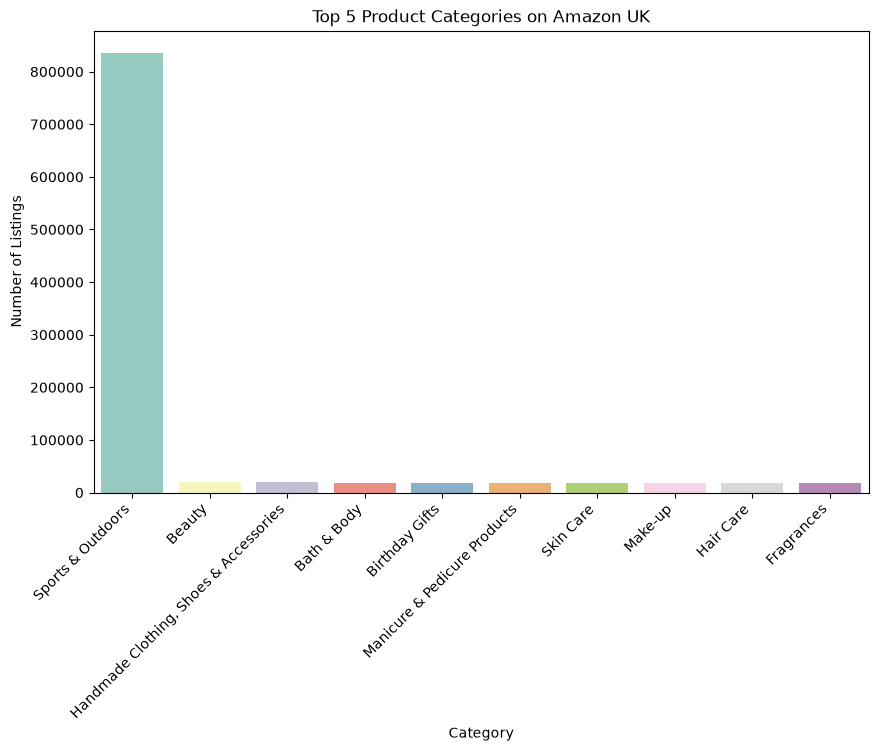

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3")

plt.title("Top 5 Product Categories on Amazon UK")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha='right')
plt.show()

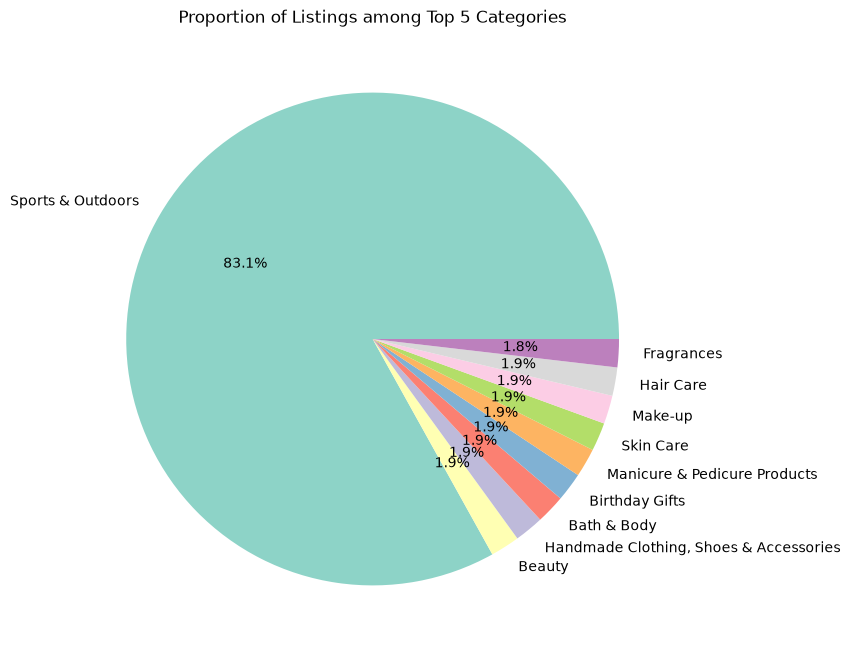

In [ ]:
plt.figure(figsize=(8, 8))
plt.pie(top_5_proportion_table.values, labels=top_5_proportion_table.index, autopct='%1.1f%%', colors=sns.color_palette("Set3"))

plt.title("Proportion of Listings among Top 10 Categories")
plt.show()

In [ ]:
## Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

## Analysing the frequency and proportion of product categories on Amazon UK provides insights into consumer preferences and market trends. 
## The bar chart illustrates the top 5 product categories based on the number of listings, while the pie chart shows the proportion of listings among the top 10 categories.

In [ ]:
## Part 2: Delving into Product Pricing

In [32]:
df_amazon.head()    

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [33]:
df_amazon_price = df_amazon[['price']]

In [34]:
df_amazon_price.mean()

price    89.243809
dtype: float64

In [35]:
df_amazon_price.median()

price    19.09
dtype: float64

In [36]:
df_amazon_price.mode()

,price
0,9.99


In [38]:
mean_price = df_amazon_price.mean()
median_price = df_amazon_price.median()
mode_price = df_amazon_price.mode()

mean_price, median_price, mode_price

(price    89.243809
 dtype: float64,
 price    19.09
 dtype: float64,
    price
 0   9.99)

In [40]:
variance_price = df_amazon_price.var()
std_dev_price = df_amazon_price.std()
min_price = df_amazon_price.min()
max_price = df_amazon_price.max()
range_price = max_price - min_price
quantiles_price = df_amazon_price.quantile([0.25, 0.5, 0.75])

print(variance_price, std_dev_price, min_price, max_price, range_price, quantiles_price)

price    119445.485323
dtype: float64 price    345.608862
dtype: float64 price    0.0
dtype: float64 price    100000.0
dtype: float64 price    100000.0
dtype: float64       price
0.25   9.99
0.50  19.09
0.75  45.99


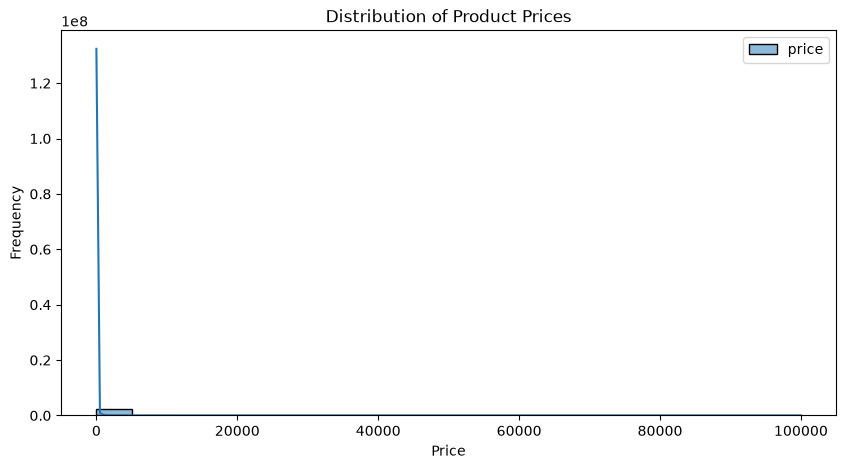

In [42]:
plt.figure(figsize=(10, 5))
sns.histplot(df_amazon_price, bins=20, kde=True)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

c:\Users\pietr\Desktop\IronHack\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2895: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Users\pietr\Desktop\IronHack\.venv\Lib\site-packages\numpy\linalg\_linalg.py:2406: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
c:\Users\pietr\Desktop\IronHack\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


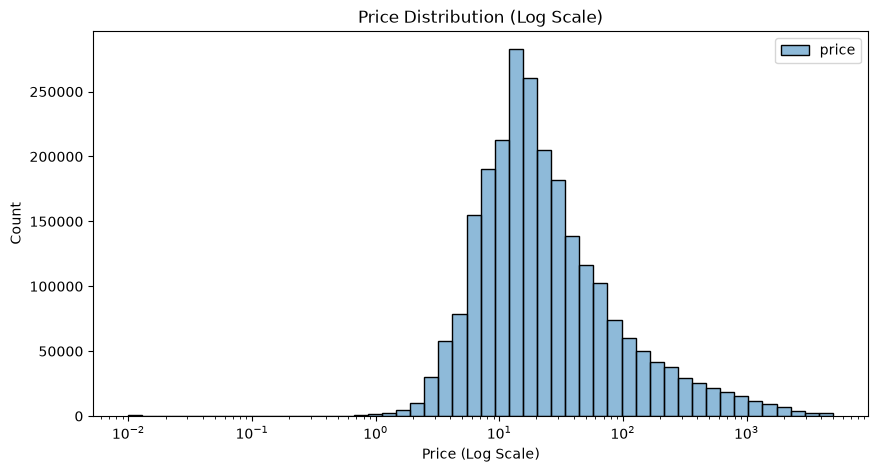

In [48]:

plt.figure(figsize=(10, 5))
sns.histplot(df_amazon_price[df_amazon_price < 5000], bins=50, log_scale=True, kde=True)
plt.title("Price Distribution (Log Scale)")
plt.xlabel("Price (Log Scale)")
plt.show()

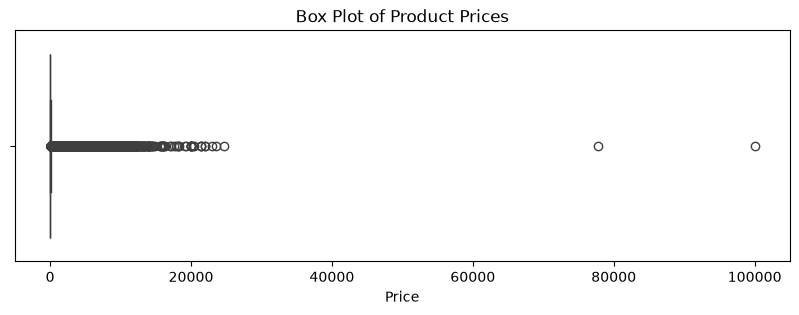

In [44]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df_amazon['price'])
plt.title("Box Plot of Product Prices")
plt.xlabel("Price")
plt.show()

In [ ]:
## As we can see from the histogram, the distribution of product prices is right-skewed, indicating that most products are priced lower, with a few high-priced outliers. 
# The log-scaled histogram provides a clearer view of the distribution, especially for lower-priced items. The box plot further highlights the presence of outliers in the price data.

In [ ]:
##Part 3: Unpacking Product Ratings

In [54]:
mean_rating = df_amazon['stars'].mean()
median_rating = df_amazon['stars'].median()
mode_rating = df_amazon['stars'].mode()[0]

In [55]:
print(f"Mean: {mean_rating:.2f}")
print(f"Median: {median_rating:.2f}")
print(f"Mode: {mode_rating:.2f}")

Mean: 2.15
Median: 0.00
Mode: 0.00


In [57]:

valid_ratings = df_amazon[df_amazon['stars'] > 0]['stars']

mean_rating = valid_ratings.mean()
median_rating = valid_ratings.median()
mode_rating = valid_ratings.mode()[0]

print(f"Mean (reviewed products): {mean_rating:.2f}")
print(f"Median (reviewed products): {median_rating:.2f}")
print(f"Mode (reviewed products): {mode_rating:.2f}")

Mean (reviewed products): 4.32
Median (reviewed products): 4.40
Mode (reviewed products): 4.50


In [ ]:
## Raw Data: Many products on Amazon have no reviews (rating = 0), which artificially pulls down the overall average.

## Filtered Data (Rated Products): Among the products that have actually received reviews, customer ratings are strongly skewed toward high values, typically clustering between 4.0 and 4.5.

In [ ]:
# variance and Standard Deviation
var_rating = df_amazon['stars'].var()
std_rating = df_amazon['stars'].std()

# Interquartile Range (IQR)
q1 = df_amazon['stars'].quantile(0.25)
q3 = df_amazon['stars'].quantile(0.75)
iqr_rating = q3 - q1

print(f"Variance: {var_rating:.2f}")
print(f"Standard Deviation: {std_rating:.2f}")
print(f"IQR: {iqr_rating:.2f}")

Variance: 4.82
Standard Deviation: 2.19
IQR: 4.40


In [ ]:
# 1. Filter out unrated products (stars == 0) to remove zero-value distortion
valid_ratings = df_amazon[df_amazon['stars'] > 0]['stars']

# 2. Calculate dispersion metrics on filtered data
var_valid = valid_ratings.var()
std_valid = valid_ratings.std()

# Calculate Interquartile Range (IQR) for filtered data
q1_valid = valid_ratings.quantile(0.25)
q3_valid = valid_ratings.quantile(0.75)
iqr_valid = q3_valid - q1_valid

# 3. Print the filtered dispersion results
print(f"Variance (filtered): {var_valid:.2f}")
print(f"Standard Deviation (filtered): {std_valid:.2f}")
print(f"IQR (filtered): {iqr_valid:.2f}")

# Note: Removing 0.0 ratings reveals that customer feedback is actually highly 
# consistent, significantly reducing the standard deviation and IQR.

Variance (filtered): 0.31
Standard Deviation (filtered): 0.56
IQR (filtered): 0.50


In [62]:
# Raw data calculation
skew_raw = df_amazon['stars'].skew()
kurt_raw = df_amazon['stars'].kurtosis()

# Filtered data calculation
skew_filtered = valid_ratings.skew()
kurt_filtered = valid_ratings.kurtosis()

In [63]:
print("--- Shape of Distribution ---")
print(f"Raw Data - Skewness: {skew_raw:.2f}, Kurtosis: {kurt_raw:.2f}")
print(f"Filtered Data - Skewness: {skew_filtered:.2f}, Kurtosis: {kurt_filtered:.2f}")

--- Shape of Distribution ---
Raw Data - Skewness: 0.08, Kurtosis: -1.93
Filtered Data - Skewness: -2.38, Kurtosis: 9.78


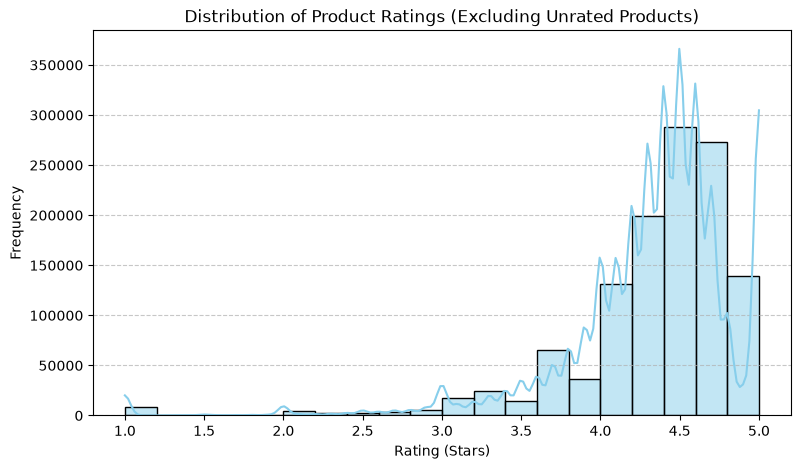

In [64]:
# 3. Point 4: Plot Histogram for Filtered Ratings
plt.figure(figsize=(9, 5))
sns.histplot(valid_ratings, bins=20, kde=True, color='skyblue')
plt.title("Distribution of Product Ratings (Excluding Unrated Products)")
plt.xlabel("Rating (Stars)")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
## Are the ratings normally distributed, or do they lean towards higher or lower values?

In [ ]:
## The ratings are not normally distributed. The filtered dataset exhibits a strong negative skewness (value $< 0$), 
# indicating a distribution with a long tail to the left and a heavy concentration of values on the right. 
## This confirms that customer reviews strongly lean towards higher values (typically between 4.0 and 4.5 stars).
## The kurtosis is positive (leptokurtic), showing a prominent peak around high ratings rather than a flat, spread-out bell curve.

In [ ]:
## Is there a specific rating that is more common?

In [ ]:
## The histogram visually demonstrates that ratings are heavily clustered between 4.1 and 4.5 stars, with 4.3 to 4.5 being the most common specific score range. 
## Extremely low ratings (1 to 2 stars) are exceptionally rare on rated products.